# Diabetes Disease Prediction

**Dataset:** diabetes_dataset.csv  
**Models:** Logistic Regression, Random Forest, XGBoost  
**Methodology:** Stratified Train/Test Split → Stratified 5-Fold CV → Final Test Evaluation

---

## 1. Imports

In [3]:
import sys
import subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", 
                       "xgboost", "scikit-learn", "pandas", "numpy", 
                       "matplotlib", "seaborn"])


0

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)

## 2. Load Dataset

In [5]:
df = pd.read_csv('diabetes_dataset.csv')
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 600 rows, 9 columns


,PatientID,Age,Gender,BMI,BloodPressure,Insulin,Glucose,DiabetesPedigreeFunction,Outcome
0,1,45,Male,37.2,74,105,102,0.204,0
1,2,24,Female,37.2,52,170,162,0.652,1
2,3,28,Female,27.5,74,170,146,0.240,1
3,4,31,Female,28.0,70,102,90,0.610,0
4,5,23,Male,24.2,58,265,101,0.614,0


## 3. Dataset Overview

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   PatientID                 600 non-null    int64  
 1   Age                       600 non-null    int64  
 2   Gender                    600 non-null    object 
 3   BMI                       600 non-null    float64
 4   BloodPressure             600 non-null    int64  
 5   Insulin                   600 non-null    int64  
 6   Glucose                   600 non-null    int64  
 7   DiabetesPedigreeFunction  600 non-null    float64
 8   Outcome                   600 non-null    int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 42.3+ KB


In [7]:
df.describe()

,PatientID,Age,BMI,BloodPressure,Insulin,Glucose,DiabetesPedigreeFunction,Outcome
count,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,300.500000,33.923333,32.068900,73.166667,132.053333,123.051667,0.472864,0.398333
std,173.349358,11.851084,6.201663,10.989700,56.214060,29.790739,0.313275,0.489963
min,1.000000,21.000000,18.980000,50.000000,18.000000,71.000000,0.087500,0.000000
25%,150.750000,24.000000,27.600000,66.000000,102.000000,101.000000,0.245000,0.000000
50%,300.500000,30.000000,32.000000,72.000000,105.000000,117.000000,0.377000,0.000000
75%,450.250000,41.000000,36.150000,80.000000,170.000000,141.000000,0.640000,1.000000
max,600.000000,69.000000,47.900000,110.000000,330.000000,197.000000,1.893000,1.000000


## 4. Data Quality Checks

In [8]:
print("--- Missing Values ---")
print(df.isnull().sum())
print("\n--- Duplicate Rows ---")
print(f"Total Duplicate Rows: {df.duplicated().sum()}")

--- Missing Values ---
PatientID                   0
Age                         0
Gender                      0
BMI                         0
BloodPressure               0
Insulin                     0
Glucose                     0
DiabetesPedigreeFunction    0
Outcome                     0
dtype: int64

--- Duplicate Rows ---
Total Duplicate Rows: 0


## 5. Remove Irrelevant Columns & Encode Categorical Features

In [9]:
# Remove non-predictive identifier
if 'PatientID' in df.columns:
    df.drop(columns=['PatientID'], inplace=True)
    print("Dropped PatientID column.")

# Encode Gender if stored as string
if df['Gender'].dtype == 'object':
    df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1}).fillna(0).astype(int)
    print("Encoded Gender: Female -> 0, Male -> 1")

df.head()

Dropped PatientID column.
Encoded Gender: Female -> 0, Male -> 1


,Age,Gender,BMI,BloodPressure,Insulin,Glucose,DiabetesPedigreeFunction,Outcome
0,45,1,37.2,74,105,102,0.204,0
1,24,0,37.2,52,170,162,0.652,1
2,28,0,27.5,74,170,146,0.240,1
3,31,0,28.0,70,102,90,0.610,0
4,23,1,24.2,58,265,101,0.614,0


## 5. Exploratory Data Analysis (EDA)

--- Target Distribution (Outcome) ---
Outcome
0    361
1    239
Name: count, dtype: int64

--- Target Percentage (%) ---
Outcome
0    60.166667
1    39.833333
Name: proportion, dtype: float64


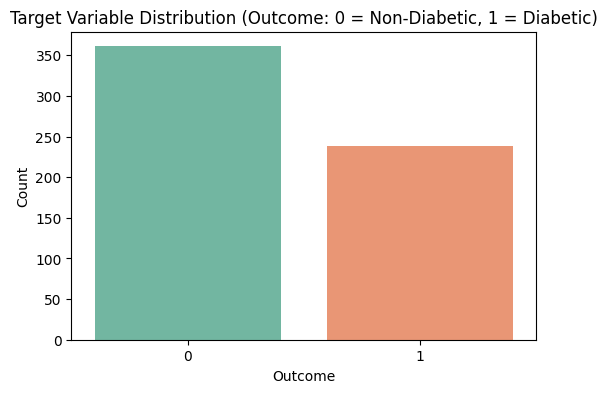

In [10]:
# Target variable distribution
print("--- Target Distribution (Outcome) ---")
print(df['Outcome'].value_counts())
print("\n--- Target Percentage (%) ---")
print(df['Outcome'].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(x='Outcome', data=df, palette='Set2')
plt.title('Target Variable Distribution (Outcome: 0 = Non-Diabetic, 1 = Diabetic)')
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.show()

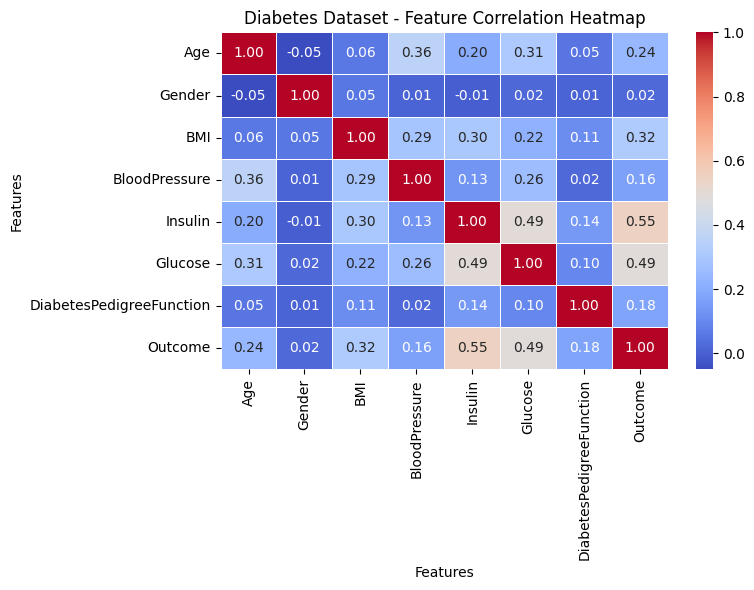

--- Correlation with Target (Outcome) ---
Outcome                     1.000000
Insulin                     0.548380
Glucose                     0.490511
BMI                         0.317636
Age                         0.241601
DiabetesPedigreeFunction    0.178671
BloodPressure               0.164065
Gender                      0.020972
Name: Outcome, dtype: float64


In [11]:
# Feature Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Diabetes Dataset - Feature Correlation Heatmap')
plt.xlabel('Features')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

print("--- Correlation with Target (Outcome) ---")
print(df.corr()['Outcome'].sort_values(ascending=False))

  Z-SCORE OUTLIER SUMMARY (|Z| > 3) — Informational Only
                 Feature   Mean  Std Dev  Min Z  Max Z  Outliers (|Z|>3) Outlier %
                     Age  33.92    11.85  -1.09   2.96                 0      0.0%
                     BMI  32.07     6.20  -2.11   2.55                 0      0.0%
           BloodPressure  73.17    10.99  -2.11   3.35                 5     0.83%
                 Insulin 132.05    56.21  -2.03   3.52                 9      1.5%
                 Glucose 123.05    29.79  -1.75   2.48                 0      0.0%
DiabetesPedigreeFunction   0.47     0.31  -1.23   4.53                 8     1.33%


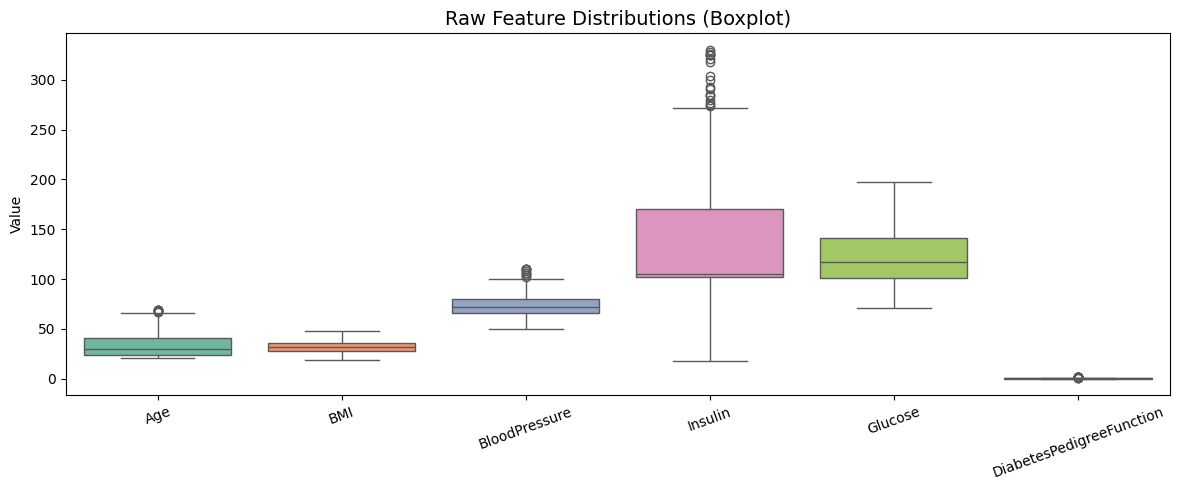

In [12]:
# Outlier check using Z-scores (informational only — raw data is NOT modified here)
num_cols = [col for col in df.columns if col not in ['Gender', 'Outcome']]

print("=" * 70)
print("  Z-SCORE OUTLIER SUMMARY (|Z| > 3) — Informational Only")
print("=" * 70)

z_summary = []
for col in num_cols:
    mean_val = df[col].mean()
    std_val  = df[col].std()
    z_scores = (df[col] - mean_val) / std_val
    count    = int((abs(z_scores) > 3).sum())
    pct      = (count / len(df)) * 100
    z_summary.append({
        'Feature': col,
        'Mean': round(mean_val, 2),
        'Std Dev': round(std_val, 2),
        'Min Z': round(z_scores.min(), 2),
        'Max Z': round(z_scores.max(), 2),
        'Outliers (|Z|>3)': count,
        'Outlier %': f"{round(pct, 2)}%"
    })

z_df = pd.DataFrame(z_summary)
print(z_df.to_string(index=False))

# Boxplot of raw features
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[num_cols], palette='Set2')
plt.xticks(range(len(num_cols)), num_cols, rotation=20)
plt.title('Raw Feature Distributions (Boxplot)', fontsize=14)
plt.ylabel('Value')
plt.tight_layout()
plt.show()

## 6. Define Features and Target

In [13]:
X = df.drop(columns=['Outcome'])
y = df['Outcome']

print(f"Features : {list(X.columns)}")
print(f"Target   : Outcome (0 = Non-Diabetic, 1 = Diabetic)")
print(f"Shape    : {X.shape}")

Features : ['Age', 'Gender', 'BMI', 'BloodPressure', 'Insulin', 'Glucose', 'DiabetesPedigreeFunction']
Target   : Outcome (0 = Non-Diabetic, 1 = Diabetic)
Shape    : (600, 7)


## 7. Train/Test Split (Stratified)

The dataset is split **before** any preprocessing. No scaling or transformation is applied to the full dataset.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set : {X_train.shape[0]} samples")
print(f"Test set     : {X_test.shape[0]} samples")
print(f"\nTraining class distribution:")
print(y_train.value_counts())
print(f"\nTest class distribution:")
print(y_test.value_counts())

Training set : 480 samples
Test set     : 120 samples

Training class distribution:
Outcome
0    289
1    191
Name: count, dtype: int64

Test class distribution:
Outcome
0    72
1    48
Name: count, dtype: int64


## 8. Preprocessing

- **Logistic Regression**: `StandardScaler` is wrapped inside a `Pipeline`. The scaler is fitted **only on training data** and applied to test data separately — preventing data leakage.
- **Random Forest & XGBoost**: Trained on raw features. Tree-based models split on thresholds and do not require feature scaling.

In [15]:
# Logistic Regression Pipeline — scaler fitted only on training data
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

# Tree-based models — no scaling required
rf_model  = RandomForestClassifier(n_estimators=100, random_state=42)
xgb_model = XGBClassifier(
    n_estimators=100, max_depth=5, learning_rate=0.05,
    random_state=42, eval_metric='logloss'
)

print("Models defined:")
print("  - Logistic Regression  -> Pipeline (StandardScaler + LR)")
print("  - Random Forest        -> raw features")
print("  - XGBoost              -> raw features")

Models defined:
  - Logistic Regression  -> Pipeline (StandardScaler + LR)
  - Random Forest        -> raw features
  - XGBoost              -> raw features


## 9. Define ML Models

## 10. Stratified 5-Fold Cross-Validation

All CV is performed **only on training data** (`X_train`, `y_train`). The test set is completely held out.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'accuracy' : 'accuracy',
    'precision': 'precision',
    'recall'   : 'recall',
    'f1'       : 'f1',
    'roc_auc'  : 'roc_auc'
}

models = {
    'Logistic Regression': lr_pipeline,
    'Random Forest'      : rf_model,
    'XGBoost'            : xgb_model
}

cv_results = {}

for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_results[name] = {
        'CV Accuracy' : scores['test_accuracy'].mean(),
        'CV Precision': scores['test_precision'].mean(),
        'CV Recall'   : scores['test_recall'].mean(),
        'CV F1'       : scores['test_f1'].mean(),
        'CV ROC-AUC'  : scores['test_roc_auc'].mean(),
        'F1 Std'      : scores['test_f1'].std(),
        'AUC Std'     : scores['test_roc_auc'].std()
    }
    print(f"[{name}]  CV F1: {cv_results[name]['CV F1']:.4f} +/- {cv_results[name]['F1 Std']:.4f}  |  CV AUC: {cv_results[name]['CV ROC-AUC']:.4f} +/- {cv_results[name]['AUC Std']:.4f}")

[Logistic Regression]  CV F1: 0.7615 +/- 0.0266  |  CV AUC: 0.8791 +/- 0.0198
[Random Forest]  CV F1: 0.8785 +/- 0.0240  |  CV AUC: 0.9391 +/- 0.0197
[XGBoost]  CV F1: 0.8592 +/- 0.0285  |  CV AUC: 0.9513 +/- 0.0124


## 11. Model Comparison (Cross-Validation Results)

         CROSS-VALIDATION PERFORMANCE COMPARISON (Training Set)
              Model  CV Accuracy  CV Precision  CV Recall  CV F1  CV ROC-AUC
Logistic Regression       0.8167        0.7888     0.7379 0.7615      0.8791
      Random Forest       0.9042        0.8858     0.8741 0.8785      0.9391
            XGBoost       0.8896        0.8704     0.8534 0.8592      0.9513


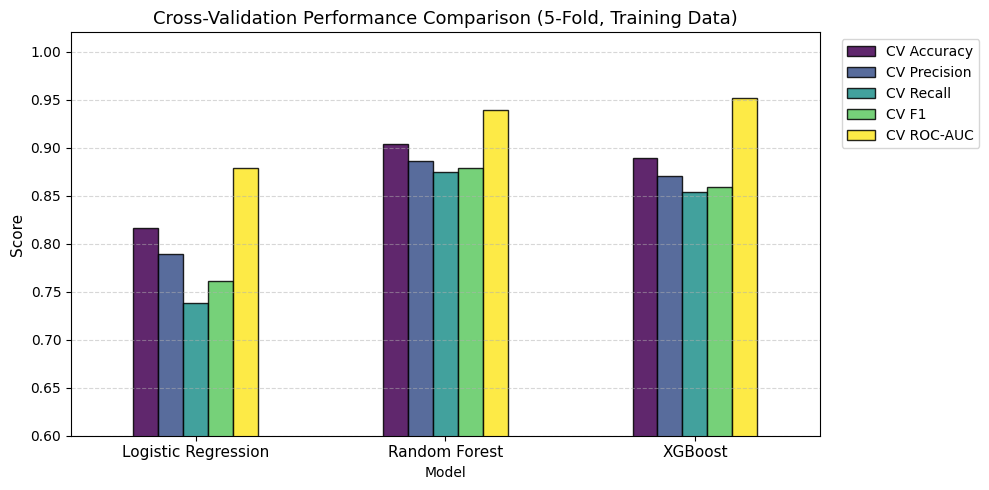

In [17]:
cv_df = pd.DataFrame({
    name: {
        'CV Accuracy' : round(res['CV Accuracy'],  4),
        'CV Precision': round(res['CV Precision'], 4),
        'CV Recall'   : round(res['CV Recall'],    4),
        'CV F1'       : round(res['CV F1'],        4),
        'CV ROC-AUC'  : round(res['CV ROC-AUC'],   4)
    }
    for name, res in cv_results.items()
}).T.reset_index().rename(columns={'index': 'Model'})

print("=" * 75)
print("         CROSS-VALIDATION PERFORMANCE COMPARISON (Training Set)")
print("=" * 75)
print(cv_df.to_string(index=False))

ax = cv_df.set_index('Model').plot(
    kind='bar', figsize=(10, 5), colormap='viridis',
    edgecolor='black', alpha=0.85
)
plt.title('Cross-Validation Performance Comparison (5-Fold, Training Data)', fontsize=13)
plt.ylabel('Score', fontsize=11)
plt.ylim(0.60, 1.02)
plt.xticks(rotation=0, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

## 12. Select Final Model

The final model is selected based on **CV F1-score**, with **CV ROC-AUC** as a tiebreaker. Test set results play no role in this decision.

In [18]:
best_model_name = max(
    cv_results,
    key=lambda m: (round(cv_results[m]['CV F1'], 4), round(cv_results[m]['CV ROC-AUC'], 4))
)

print("=" * 65)
print(f"  SELECTED FINAL MODEL: {best_model_name.upper()}")
print("  Selection criterion: Best CV F1-Score (ROC-AUC as tiebreaker)")
print("=" * 65)
print(f"  CV Accuracy  : {cv_results[best_model_name]['CV Accuracy']:.4f}")
print(f"  CV Precision : {cv_results[best_model_name]['CV Precision']:.4f}")
print(f"  CV Recall    : {cv_results[best_model_name]['CV Recall']:.4f}")
print(f"  CV F1-Score  : {cv_results[best_model_name]['CV F1']:.4f} +/- {cv_results[best_model_name]['F1 Std']:.4f}")
print(f"  CV ROC-AUC   : {cv_results[best_model_name]['CV ROC-AUC']:.4f} +/- {cv_results[best_model_name]['AUC Std']:.4f}")

  SELECTED FINAL MODEL: RANDOM FOREST
  Selection criterion: Best CV F1-Score (ROC-AUC as tiebreaker)
  CV Accuracy  : 0.9042
  CV Precision : 0.8858
  CV Recall    : 0.8741
  CV F1-Score  : 0.8785 +/- 0.0240
  CV ROC-AUC   : 0.9391 +/- 0.0197


## 13. Train Final Model on Full Training Set

In [19]:
final_model = models[best_model_name]
final_model.fit(X_train, y_train)
print(f"{best_model_name} retrained on full training set ({X_train.shape[0]} samples).")

Random Forest retrained on full training set (480 samples).


## 14. Final Test Evaluation

The test set is evaluated exactly **once** — after the final model is selected and trained. These results are not used for model selection.

In [20]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

test_accuracy  = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred)
test_recall    = recall_score(y_test, y_pred)
test_f1        = f1_score(y_test, y_pred)
test_auc       = roc_auc_score(y_test, y_prob)

print("=" * 65)
print(f"  FINAL TEST EVALUATION — {best_model_name.upper()}")
print("=" * 65)
print(f"  Accuracy  : {test_accuracy:.4f}")
print(f"  Precision : {test_precision:.4f}")
print(f"  Recall    : {test_recall:.4f}")
print(f"  F1-Score  : {test_f1:.4f}")
print(f"  ROC-AUC   : {test_auc:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=['Non-Diabetic', 'Diabetic']))

test_table = pd.DataFrame([{
    'Model'         : best_model_name,
    'Test Accuracy' : round(test_accuracy,  4),
    'Test Precision': round(test_precision, 4),
    'Test Recall'   : round(test_recall,    4),
    'Test F1'       : round(test_f1,        4),
    'Test ROC-AUC'  : round(test_auc,       4)
}])
print("--- Final Test Result Table ---")
print(test_table.to_string(index=False))

  FINAL TEST EVALUATION — RANDOM FOREST
  Accuracy  : 0.9167
  Precision : 0.9318
  Recall    : 0.8542
  F1-Score  : 0.8913
  ROC-AUC   : 0.9502

              precision    recall  f1-score   support

Non-Diabetic       0.91      0.96      0.93        72
    Diabetic       0.93      0.85      0.89        48

    accuracy                           0.92       120
   macro avg       0.92      0.91      0.91       120
weighted avg       0.92      0.92      0.92       120

--- Final Test Result Table ---
        Model  Test Accuracy  Test Precision  Test Recall  Test F1  Test ROC-AUC
Random Forest         0.9167          0.9318       0.8542   0.8913        0.9502


## 15. Confusion Matrix (Final Model — Test Set)

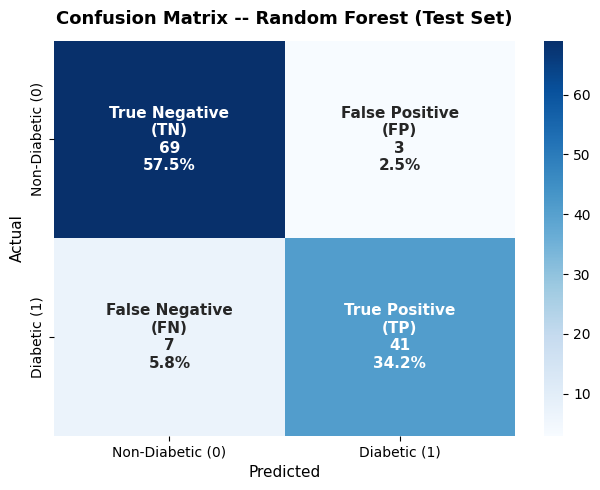

Sensitivity (Recall)     : 0.8542
Specificity              : 0.9583
Positive Predictive Value: 0.9318
Negative Predictive Value: 0.9079


In [21]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

group_names  = ['True Negative\n(TN)', 'False Positive\n(FP)', 'False Negative\n(FN)', 'True Positive\n(TP)']
group_counts = [f"{v:d}" for v in cm.flatten()]
group_pct    = [f"{v:.1%}" for v in cm.flatten() / np.sum(cm)]
labels = [f"{n}\n{c}\n{p}" for n, c, p in zip(group_names, group_counts, group_pct)]
labels = np.array(labels).reshape(2, 2)

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(
    cm, annot=labels, fmt='', cmap='Blues', cbar=True,
    xticklabels=['Non-Diabetic (0)', 'Diabetic (1)'],
    yticklabels=['Non-Diabetic (0)', 'Diabetic (1)'],
    annot_kws={'fontsize': 11, 'fontweight': 'bold'}
)
plt.title(f'Confusion Matrix -- {best_model_name} (Test Set)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Predicted', fontsize=11)
plt.ylabel('Actual', fontsize=11)
plt.tight_layout()
plt.show()

sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
ppv         = tp / (tp + fp) if (tp + fp) > 0 else 0
npv         = tn / (tn + fn) if (tn + fn) > 0 else 0

print(f"Sensitivity (Recall)     : {sensitivity:.4f}")
print(f"Specificity              : {specificity:.4f}")
print(f"Positive Predictive Value: {ppv:.4f}")
print(f"Negative Predictive Value: {npv:.4f}")

## 16. ROC Curve (Final Model — Test Set)

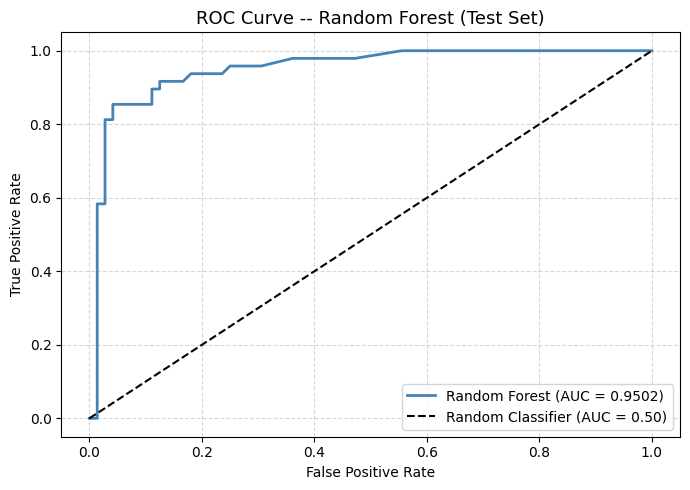

In [22]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc_score   = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='steelblue', linewidth=2,
         label=f"{best_model_name} (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.50)')
plt.title(f'ROC Curve -- {best_model_name} (Test Set)', fontsize=13)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 17. Patient Prediction / Inference Function

Applies the same preprocessing used during training and returns the prediction and probability only.

> **Note:** Clinical recommendations are NOT generated here. They will be added through the RAG + LLM stage in a later phase.

In [23]:
def predict_diabetes(patient_data: dict) -> dict:
    """
    Predict diabetes for a new patient using the selected final model.

    Input
    -----
    patient_data : dict
        Raw unscaled clinical values:
          Age                      - years
          Gender                   - 0 (Female) or 1 (Male), or 'Female'/'Male'
          BMI                      - kg/m^2
          BloodPressure            - Diastolic mm Hg
          Insulin                  - mu U/ml
          Glucose                  - Fasting Plasma Glucose mg/dL
          DiabetesPedigreeFunction - Genetic predisposition score

    Output
    ------
    dict: Model name, Prediction label, Probability (0 to 1)
    """
    patient_dict = patient_data.copy()

    # Handle string Gender input
    if isinstance(patient_dict.get('Gender'), str):
        patient_dict['Gender'] = 1 if patient_dict['Gender'].strip().lower() in ['male', 'm'] else 0

    patient_df = pd.DataFrame([patient_dict])
    patient_df = patient_df[X_train.columns]   # ensure column order matches training

    pred = int(final_model.predict(patient_df)[0])
    prob = float(final_model.predict_proba(patient_df)[0, 1])

    return {
        'Model'      : best_model_name,
        'Prediction' : 'Diabetic' if pred == 1 else 'Non-Diabetic',
        'Probability': round(prob, 4)
    }


# Sample predictions
healthy_patient = {
    'Age': 25, 'Gender': 'Female', 'BMI': 22.4,
    'BloodPressure': 72, 'Insulin': 15.0,
    'Glucose': 90, 'DiabetesPedigreeFunction': 0.18
}
diabetic_patient = {
    'Age': 54, 'Gender': 'Male', 'BMI': 34.5,
    'BloodPressure': 88, 'Insulin': 185.0,
    'Glucose': 175, 'DiabetesPedigreeFunction': 0.78
}

print("Patient 1 (Healthy):")
result1 = predict_diabetes(healthy_patient)
print(f"  Prediction  : {result1['Prediction']}")
print(f"  Probability : {result1['Probability']}")

print("\nPatient 2 (Suspected Diabetes):")
result2 = predict_diabetes(diabetic_patient)
print(f"  Prediction  : {result2['Prediction']}")
print(f"  Probability : {result2['Probability']}")

Patient 1 (Healthy):
  Prediction  : Non-Diabetic
  Probability : 0.02

Patient 2 (Suspected Diabetes):
  Prediction  : Diabetic
  Probability : 0.9


## 18. Final Summary

In [24]:
print("=" * 70)
print("  DIABETES PREDICTION -- FINAL SUMMARY")
print("=" * 70)
print(f"  Dataset          : diabetes_dataset.csv")
print(f"  Features         : {list(X.columns)}")
print(f"  Train/Test Split : 80% / 20% (Stratified)")
print(f"  CV Strategy      : Stratified 5-Fold on training data only")
print(f"  Model Selection  : CV F1-Score (ROC-AUC as tiebreaker)")
print(f"  Selected Model   : {best_model_name}")
print()
print("  Cross-Validation Results (Training Data):")
print(f"    CV Accuracy  : {cv_results[best_model_name]['CV Accuracy']:.4f}")
print(f"    CV Precision : {cv_results[best_model_name]['CV Precision']:.4f}")
print(f"    CV Recall    : {cv_results[best_model_name]['CV Recall']:.4f}")
print(f"    CV F1-Score  : {cv_results[best_model_name]['CV F1']:.4f}")
print(f"    CV ROC-AUC   : {cv_results[best_model_name]['CV ROC-AUC']:.4f}")
print()
print("  Final Test Set Results (Reported once, after model selection):")
print(f"    Test Accuracy  : {test_accuracy:.4f}")
print(f"    Test Precision : {test_precision:.4f}")
print(f"    Test Recall    : {test_recall:.4f}")
print(f"    Test F1-Score  : {test_f1:.4f}")
print(f"    Test ROC-AUC   : {test_auc:.4f}")
print()
print("  Next stages (not implemented yet):")
print("    - SHAP Feature Explanations")
print("    - RAG + ChromaDB (Clinical Evidence Retrieval)")
print("    - LLM (Evidence-Grounded Explanation)")
print("    - Agentic AI layer")
print("=" * 70)

  DIABETES PREDICTION -- FINAL SUMMARY
  Dataset          : diabetes_dataset.csv
  Features         : ['Age', 'Gender', 'BMI', 'BloodPressure', 'Insulin', 'Glucose', 'DiabetesPedigreeFunction']
  Train/Test Split : 80% / 20% (Stratified)
  CV Strategy      : Stratified 5-Fold on training data only
  Model Selection  : CV F1-Score (ROC-AUC as tiebreaker)
  Selected Model   : Random Forest

  Cross-Validation Results (Training Data):
    CV Accuracy  : 0.9042
    CV Precision : 0.8858
    CV Recall    : 0.8741
    CV F1-Score  : 0.8785
    CV ROC-AUC   : 0.9391

  Final Test Set Results (Reported once, after model selection):
    Test Accuracy  : 0.9167
    Test Precision : 0.9318
    Test Recall    : 0.8542
    Test F1-Score  : 0.8913
    Test ROC-AUC   : 0.9502

  Next stages (not implemented yet):
    - SHAP Feature Explanations
    - RAG + ChromaDB (Clinical Evidence Retrieval)
    - LLM (Evidence-Grounded Explanation)
    - Agentic AI layer
